
# Avtomobilin qiymətinin proqnozlaşdırılması

**Məqsəd:** İşlənmiş avtomobillərin xüsusiyyətlərinə əsasən qiymətini proqnozlaşdıran maşın öyrənməsi modeli qurmaq.

**İstifadə olunan məlumatlar:** Used_Cars_Homework.csv

**Hədəf dəyişən:** `price_azn`

**Model:** LinearRegression


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

pd.set_option("display.max_columns", None)

print("Kitabxanalar uğurla yükləndi!")


Kitabxanalar uğurla yükləndi!


In [2]:

df = pd.read_csv("Used_Cars_Homework.csv")

print("Məlumatlar uğurla yükləndi.")


Məlumatlar uğurla yükləndi.


In [3]:
import pandas as pd

df = pd.read_csv("Used_Cars_Homework.csv")

print("Məlumatlar uğurla yükləndi.")

Məlumatlar uğurla yükləndi.


In [4]:
df.head(10)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,16950
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,37335
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,30593
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,22641
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,41672
5,11,89859.0,2.0,120,Hyundai,petrol,automatic,yes,18479
6,6,124854.0,3.0,196,Toyota,diesel,automatic,no,38680
7,4,70952.0,1.8,95,BMW,petrol,automatic,no,40016
8,15,248400.0,1.8,90,Hyundai,hybrid,automatic,no,19668
9,11,153076.0,2.0,140,BMW,hybrid,automatic,no,36190


In [5]:
print("Sətir və sütun sayı:", df.shape)
print("Sətirlərin sayı:", df.shape[0])
print("Sütunların sayı:", df.shape[1])

Sətir və sütun sayı: (300, 9)
Sətirlərin sayı: 300
Sütunların sayı: 9


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age_years         300 non-null    int64  
 1   mileage_km        283 non-null    float64
 2   engine_l          284 non-null    float64
 3   power_hp          300 non-null    int64  
 4   brand             300 non-null    str    
 5   fuel_type         287 non-null    str    
 6   transmission      290 non-null    str    
 7   accident_history  300 non-null    str    
 8   price_azn         300 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.2 KB


In [7]:
print("Hər sütundakı çatışmayan dəyərlər:")
display(df.isnull().sum())

Hər sütundakı çatışmayan dəyərlər:


age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64

In [8]:
df.describe()

,age_years,mileage_km,engine_l,power_hp,price_azn
count,300.000000,283.000000,284.000000,300.000000,300.000000
mean,7.850000,118302.176678,1.901761,123.270000,27806.573333
std,4.147066,73652.009931,0.581484,39.903861,9772.778467
min,1.000000,8659.000000,1.200000,57.000000,3805.000000
25%,4.000000,54862.500000,1.400000,93.000000,21865.500000
50%,8.000000,112308.000000,1.800000,113.000000,27458.500000
75%,11.000000,166869.500000,2.500000,151.250000,34844.750000
max,15.000000,334305.000000,3.000000,218.000000,51396.000000


In [9]:
print("Minimum qiymət:", df["price_azn"].min(), "AZN")
print("Maksimum qiymət:", df["price_azn"].max(), "AZN")
print("Orta qiymət:", round(df["price_azn"].mean(), 2), "AZN")

Minimum qiymət: 3805 AZN
Maksimum qiymət: 51396 AZN
Orta qiymət: 27806.57 AZN



## İlkin təhlilin nəticəsi

Məlumat dəstində avtomobillərin yaşı, yürüş məsafəsi, mühərrik həcmi, gücü, markası, yanacaq növü, sürətlər qutusu və qəza tarixçəsi verilmişdir.

`price_azn` sütunu modelin proqnozlaşdıracağı hədəf dəyişəndir. İlkin təhlildə məlumatların ölçüsü, tipləri, çatışmayan dəyərləri və ədədi sütunların statistikası araşdırılmışdır.

Çatışmayan dəyərlər modelin hazırlanması mərhələsində doldurulacaq.


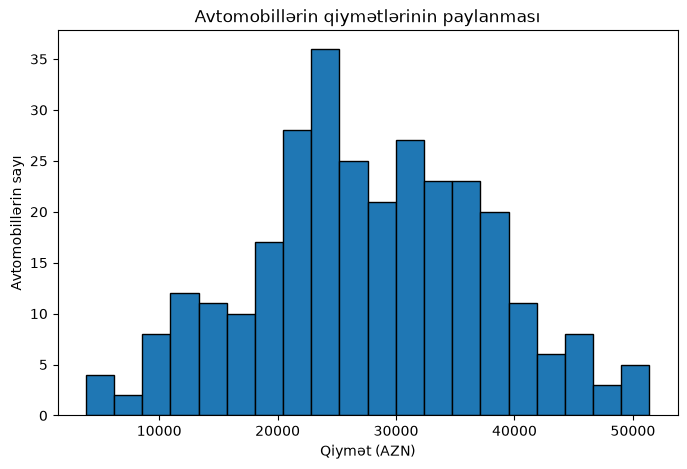

In [10]:

plt.figure(figsize=(8, 5))

plt.hist(df["price_azn"], bins=20, edgecolor="black")

plt.title("Avtomobillərin qiymətlərinin paylanması")
plt.xlabel("Qiymət (AZN)")
plt.ylabel("Avtomobillərin sayı")

plt.show()



**Nəticə:** Histoqram avtomobillərin hansı qiymət aralıqlarında daha çox toplandığını göstərir. Qiymətlərin paylanmasını və çox aşağı və ya yüksək qiymətlərin olub-olmadığını bu qrafik vasitəsilə araşdırmaq mümkündür.


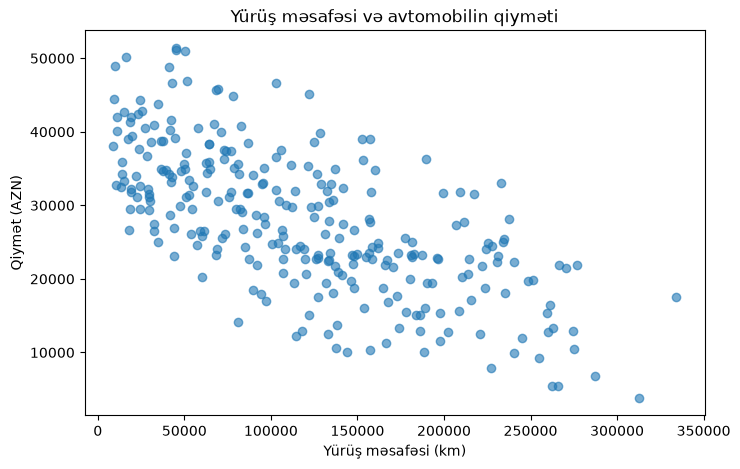

In [11]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["mileage_km"],
    df["price_azn"],
    alpha=0.6
)

plt.title("Yürüş məsafəsi və avtomobilin qiyməti")
plt.xlabel("Yürüş məsafəsi (km)")
plt.ylabel("Qiymət (AZN)")

plt.show()


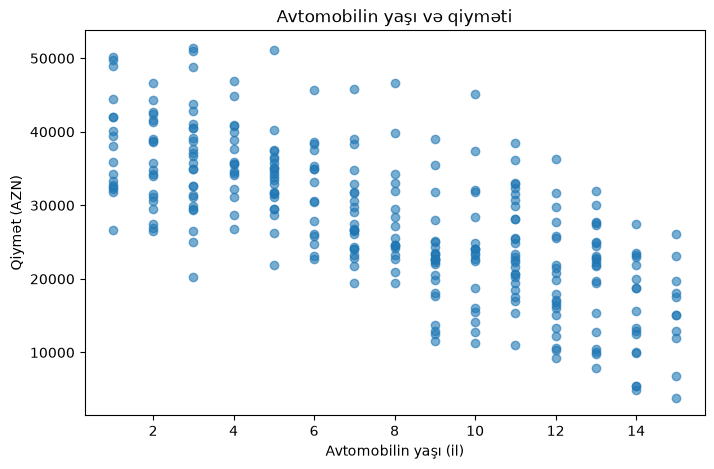

In [12]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["age_years"],
    df["price_azn"],
    alpha=0.6
)

plt.title("Avtomobilin yaşı və qiyməti")
plt.xlabel("Avtomobilin yaşı (il)")
plt.ylabel("Qiymət (AZN)")

plt.show()


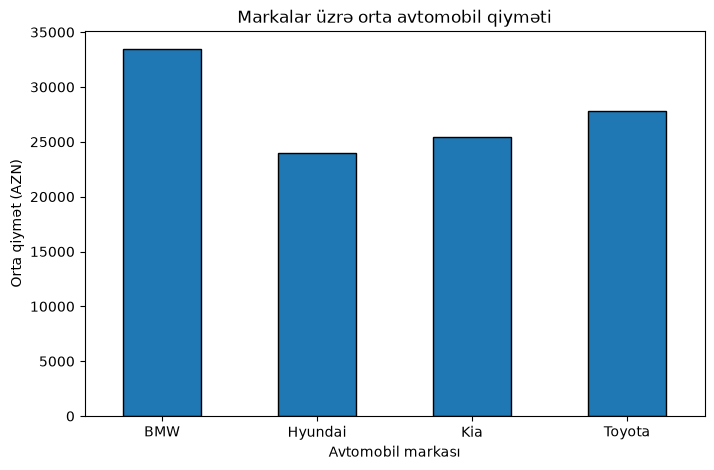

In [13]:

average_price = df.groupby("brand")["price_azn"].mean()

plt.figure(figsize=(8, 5))

average_price.plot(kind="bar", edgecolor="black")

plt.title("Markalar üzrə orta avtomobil qiyməti")
plt.xlabel("Avtomobil markası")
plt.ylabel("Orta qiymət (AZN)")
plt.xticks(rotation=0)

plt.show()


## 5. Məlumatların hazırlanması (Data Preprocessing)

Bu mərhələdə məlumatları maşın öyrənməsi üçün hazırlayırıq. Boş dəyərlər doldurulur, mətn tipli məlumatlar rəqəmlərə çevrilir və ədədi xüsusiyyətlər miqyaslanır. Bu əməliyyatlar modelin məlumatlardan düzgün öyrənməsinə kömək edir.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Maşın öyrənməsi kitabxanaları uğurla yükləndi!")

Maşın öyrənməsi kitabxanaları uğurla yükləndi!


In [15]:
print("Hər sütundakı boş dəyərlərin sayı:")
print(df.isnull().sum())

Hər sütundakı boş dəyərlərin sayı:
age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64


In [16]:
df["mileage_per_year"] = (
    df["mileage_km"] / df["age_years"].replace(0, np.nan)
)

display(df[[
    "age_years",
    "mileage_km",
    "mileage_per_year",
    "price_azn"
]].head(10))

,age_years,mileage_km,mileage_per_year,price_azn
0,11,97064.0,8824.0,16950
1,10,74340.0,7434.0,37335
2,6,69312.0,11552.0,30593
3,8,126280.0,15785.0,22641
4,2,42026.0,21013.0,41672
5,11,89859.0,8169.0,18479
6,6,124854.0,20809.0,38680
7,4,70952.0,17738.0,40016
8,15,248400.0,16560.0,19668
9,11,153076.0,13916.0,36190


In [17]:
X = df.drop(columns=["price_azn"]).copy()
y = df["price_azn"].copy()

print("Xüsusiyyətlərin ölçüsü:", X.shape)
print("Hədəf dəyişəninin ölçüsü:", y.shape)


Xüsusiyyətlərin ölçüsü: (300, 9)
Hədəf dəyişəninin ölçüsü: (300,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Təlim məlumatlarının sayı:", len(X_train))
print("Test məlumatlarının sayı:", len(X_test))

Təlim məlumatlarının sayı: 240
Test məlumatlarının sayı: 60


### 6. Məlumatların emalı

Maşın öyrənməsi alqoritmləri məlumatların düzgün formatda olmasını tələb edir. Ədədi və kateqorik sütunlar fərqli üsullarla emal edilir. Ədədi sütunlarda boş dəyərlər medianla, kateqorik sütunlarda isə ən çox təkrarlanan qiymətlə doldurula bilər.

In [19]:
numeric_features = [
    "age_years",
    "mileage_km",
    "engine_l",
    "power_hp",
    "mileage_per_year"
]

categorical_features = [
    "brand",
    "fuel_type",
    "transmission",
    "accident_history"
]

print("Ədədi sütunlar:", numeric_features)
print("Kateqorik sütunlar:", categorical_features)

Ədədi sütunlar: ['age_years', 'mileage_km', 'engine_l', 'power_hp', 'mileage_per_year']
Kateqorik sütunlar: ['brand', 'fuel_type', 'transmission', 'accident_history']


In [20]:
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_numeric = numeric_imputer.fit_transform(
    X_train[numeric_features]
)

X_train_categorical = categorical_imputer.fit_transform(
    X_train[categorical_features]
)

print("Ədədi boş dəyərlər medianla dolduruldu.")
print("Kateqorik boş dəyərlər ən çox təkrarlanan qiymətlə dolduruldu.")

Ədədi boş dəyərlər medianla dolduruldu.
Kateqorik boş dəyərlər ən çox təkrarlanan qiymətlə dolduruldu.


In [21]:
encoder = OneHotEncoder(handle_unknown="ignore")

encoded_brands = encoder.fit_transform(
    X_train[["brand"]]
)

print("Markalar:")
print(encoder.categories_[0])

print("Kodlaşdırılmış məlumatların ölçüsü:")
print(encoded_brands.shape)

Markalar:
['BMW' 'Hyundai' 'Kia' 'Toyota']
Kodlaşdırılmış məlumatların ölçüsü:
(240, 4)


In [22]:
scaler_standard = StandardScaler()

mileage_train = X_train[["mileage_km"]].copy()
mileage_train["mileage_km"] = mileage_train["mileage_km"].fillna(
    mileage_train["mileage_km"].median()
)

standard_scaled = scaler_standard.fit_transform(mileage_train)

print("İlk 5 StandardScaler nəticəsi:")
print(standard_scaled[:5])

İlk 5 StandardScaler nəticəsi:
[[-0.92873738]
 [-0.52296007]
 [ 0.08442863]
 [-0.04450497]
 [-1.45671106]]


In [23]:
scaler_minmax = MinMaxScaler()

minmax_scaled = scaler_minmax.fit_transform(mileage_train)

print("İlk 5 MinMaxScaler nəticəsi:")
print(minmax_scaled[:5])


İlk 5 MinMaxScaler nəticəsi:
[[0.13514983]
 [0.22392721]
 [0.35681384]
 [0.3286053 ]
 [0.01963789]]


## 7. Linear Regression modelinin qurulması

Bu layihədə avtomobil qiymətlərini proqnozlaşdırmaq üçün Linear Regression alqoritmindən istifadə edəcəyik. Ədədi məlumatlar medianla doldurulacaq və StandardScaler ilə miqyaslanacaq. Kateqorik məlumatların boş dəyərləri ən çox təkrarlanan qiymətlə doldurulacaq və One-Hot Encoding ilə rəqəmsal formaya çevriləcək.

In [24]:
# Ədədi sütunların emalı
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Kateqorik sütunların emalı
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Bütün emal üsullarını birləşdiririk
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Məlumatların emalı sistemi hazırdır!")


Məlumatların emalı sistemi hazırdır!


In [25]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Linear Regression modeli yaradıldı!")

Linear Regression modeli yaradıldı!


In [26]:
model.fit(X_train, y_train)

print("Model uğurla öyrədildi!")

Model uğurla öyrədildi!


In [27]:
y_pred = model.predict(X_test)

print("İlk 10 həqiqi qiymət:")
print(y_test.head(10).to_list())

print("\nİlk 10 proqnozlaşdırılmış qiymət:")
print(np.round(y_pred[:10], 2))

İlk 10 həqiqi qiymət:
[34837, 34946, 32214, 36190, 25000, 26522, 22711, 33061, 18479, 25003]

İlk 10 proqnozlaşdırılmış qiymət:
[32094.81 33157.9  31152.66 35780.66 23648.31 27360.1  24210.68 32078.44
 19693.81 23457.43]


## 8. Modelin qiymətləndirilməsi

Modelin keyfiyyətini yoxlamaq üçün MAE, MSE, RMSE və R² metriklərindən istifadə edəcəyik. Bu metriklər proqnozlaşdırılmış qiymətlərlə real qiymətlər arasındakı fərqi və modelin məlumatlara uyğunluğunu qiymətləndirməyə kömək edir.

In [28]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Modelin qiymətləndirilməsi:")
print("-" * 35)
print(f"MAE:  {mae:.2f} AZN")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f} AZN")
print(f"R²:   {r2:.4f}")


Modelin qiymətləndirilməsi:
-----------------------------------
MAE:  1414.62 AZN
MSE:  2886404.32
RMSE: 1698.94 AZN
R²:   0.9718


In [29]:
comparison = pd.DataFrame({
    "Real qiymət (AZN)": y_test.to_numpy(),
    "Proqnoz (AZN)": np.round(y_pred, 2)
})

comparison["Fərq (AZN)"] = (
    comparison["Real qiymət (AZN)"] - comparison["Proqnoz (AZN)"]
)

display(comparison.head(10))

,Real qiymət (AZN),Proqnoz (AZN),Fərq (AZN)
0,34837,32094.81,2742.19
1,34946,33157.90,1788.10
2,32214,31152.66,1061.34
3,36190,35780.66,409.34
4,25000,23648.31,1351.69
5,26522,27360.10,-838.10
6,22711,24210.68,-1499.68
7,33061,32078.44,982.56
8,18479,19693.81,-1214.81
9,25003,23457.43,1545.57


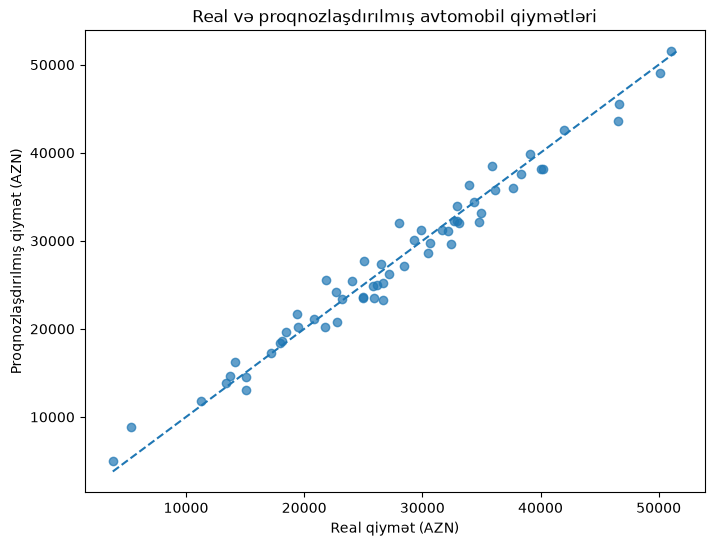

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Real və proqnozlaşdırılmış avtomobil qiymətləri")
plt.xlabel("Real qiymət (AZN)")
plt.ylabel("Proqnozlaşdırılmış qiymət (AZN)")
plt.show()

## 9. Cross-Validation

Modelin nəticələrinin yalnız bir təlim-test bölgüsündən asılı olmadığını yoxlamaq üçün 5-Fold Cross-Validation tətbiq edəcəyik. Hər dövrdə modelin R² göstəricisi hesablanacaq və nəticələrin orta qiyməti tapılacaq.

In [31]:
from sklearn.model_selection import cross_val_score

print("Cross-Validation kitabxanası hazırdır!")

Cross-Validation kitabxanası hazırdır!


In [32]:
cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("Hər yoxlamanın R² nəticəsi:")
print(np.round(cv_scores, 4))

print("\nOrta R²:", round(cv_scores.mean(), 4))
print("Standart kənarlaşma:", round(cv_scores.std(), 4))

Hər yoxlamanın R² nəticəsi:
[0.9591 0.9407 0.9365 0.9484 0.949 ]

Orta R²: 0.9467
Standart kənarlaşma: 0.0078


**Nəticə:**

Cross-Validation modelin müxtəlif məlumat hissələrində necə işlədiyini qiymətləndirmək üçün istifadə olunur. 5-Fold üsulunda məlumatlar beş hissəyə bölünür və beş ayrı yoxlama aparılır. Orta R² modelin ümumi uyğunluğu, standart kənarlaşma isə nəticələrin sabitliyi barədə məlumat verir.

## 10. Learning Curve

Learning Curve təlim məlumatlarının sayı ilə modelin nəticələri arasındakı əlaqəni göstərir. Təlim və yoxlama nəticələrini müqayisə etməklə modelin öyrənmə prosesini və mümkün overfitting problemini araşdıra bilərik.


In [33]:
from sklearn.model_selection import learning_curve

print("Learning Curve üçün kitabxana hazırdır!")

Learning Curve üçün kitabxana hazırdır!


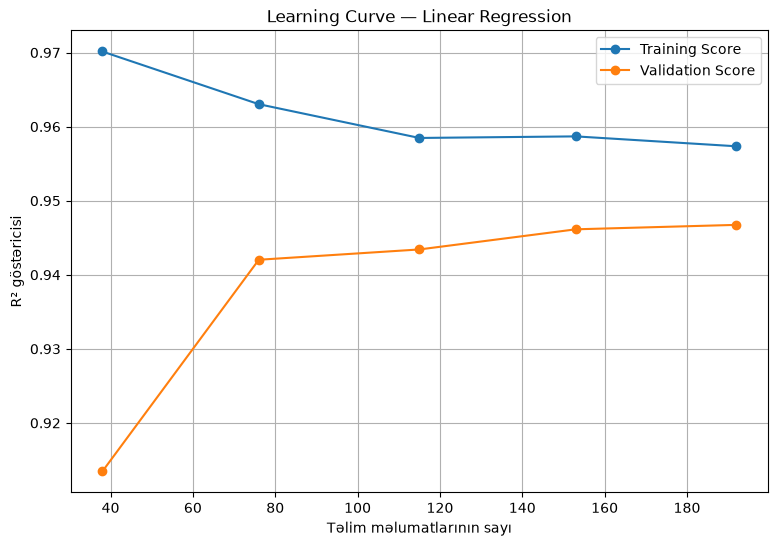

In [34]:
train_sizes, train_scores, validation_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.figure(figsize=(9, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training Score"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Validation Score"
)

plt.title("Learning Curve — Linear Regression")
plt.xlabel("Təlim məlumatlarının sayı")
plt.ylabel("R² göstəricisi")
plt.legend()
plt.grid(True)
plt.show()

**Nəticə:**

Learning Curve modelin təlim və yoxlama məlumatlarında necə nəticə göstərdiyini araşdırmağa imkan verir. Təlim məlumatlarının sayı artdıqca göstəricilərin necə dəyişdiyi müşahidə olunur. Bu qrafik overfitting və underfitting ehtimalını qiymətləndirmək üçün istifadə edilir.

## 11. Yeni avtomobillər üçün qiymət proqnozu

Bu mərhələdə öyrədilmiş Linear Regression modelindən istifadə edərək yeni avtomobillərin qiymətlərini proqnozlaşdıracağıq. Avtomobillərin yaşı, yürüşü, mühərrik həcmi, at gücü, markası, yanacaq növü, sürətlər qutusu və qəza tarixçəsi modelə təqdim edilir.

In [35]:
new_cars = pd.DataFrame([
    {
        "age_years": 5,
        "mileage_km": 75000,
        "engine_l": 1.6,
        "power_hp": 110,
        "brand": "Toyota",
        "fuel_type": "petrol",
        "transmission": "automatic",
        "accident_history": "no"
    },
    {
        "age_years": 10,
        "mileage_km": 180000,
        "engine_l": 2.0,
        "power_hp": 140,
        "brand": "Hyundai",
        "fuel_type": "diesel",
        "transmission": "manual",
        "accident_history": "yes"
    },
    {
        "age_years": 3,
        "mileage_km": 40000,
        "engine_l": 2.5,
        "power_hp": 170,
        "brand": "BMW",
        "fuel_type": "petrol",
        "transmission": "automatic",
        "accident_history": "no"
    }
])

display(new_cars)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history
0,5,75000,1.6,110,Toyota,petrol,automatic,no
1,10,180000,2.0,140,Hyundai,diesel,manual,yes
2,3,40000,2.5,170,BMW,petrol,automatic,no


In [36]:
new_cars["mileage_per_year"] = (
    new_cars["mileage_km"]
    / new_cars["age_years"].replace(0, np.nan)
)

display(new_cars)


,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,mileage_per_year
0,5,75000,1.6,110,Toyota,petrol,automatic,no,15000.000000
1,10,180000,2.0,140,Hyundai,diesel,manual,yes,18000.000000
2,3,40000,2.5,170,BMW,petrol,automatic,no,13333.333333


In [37]:
predicted_prices = model.predict(new_cars)

results = new_cars.copy()
results["predicted_price_azn"] = np.round(predicted_prices, 2)

display(results[[
    "brand",
    "age_years",
    "mileage_km",
    "predicted_price_azn"
]])

,brand,age_years,mileage_km,predicted_price_azn
0,Toyota,5,75000,31170.63
1,Hyundai,10,180000,15912.01
2,BMW,3,40000,48791.50


**Nəticə:**

Öyrədilmiş Linear Regression modeli yeni avtomobillərin xüsusiyyətlərinə əsasən onların qiymətlərini proqnozlaşdırır. Əvvəlcə yeni məlumatlar təlim zamanı istifadə olunan xüsusiyyətlərlə uyğunlaşdırılır, sonra model vasitəsilə qiymətlər hesablanır. Alınan nəticələr təxmini qiymətlərdir və real bazar qiymətlərindən fərqlənə bilər.

## 12. Proqnozların vizuallaşdırılması

Yeni avtomobillər üçün hesablanmış qiymətləri sütun qrafiki vasitəsilə müqayisə edəcəyik. Bu qrafik hər avtomobil üçün modelin verdiyi qiymət təxminini göstərir.


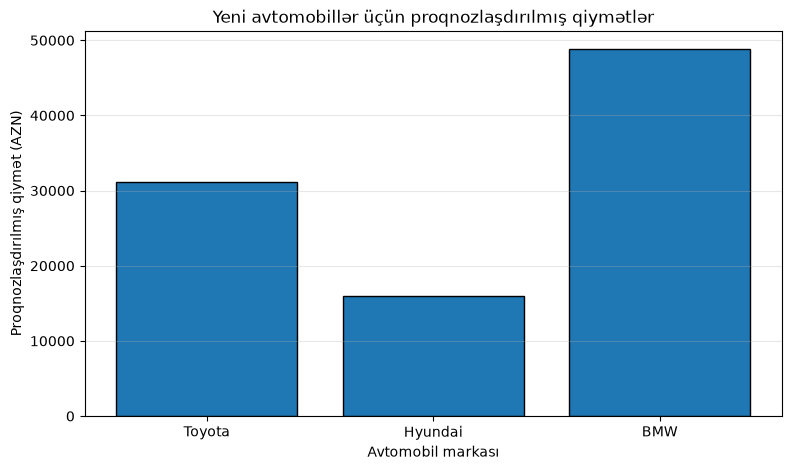

In [38]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["brand"],
    results["predicted_price_azn"],
    edgecolor="black"
)

plt.title("Yeni avtomobillər üçün proqnozlaşdırılmış qiymətlər")
plt.xlabel("Avtomobil markası")
plt.ylabel("Proqnozlaşdırılmış qiymət (AZN)")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [39]:
final_results = results[[
    "brand",
    "age_years",
    "mileage_km",
    "engine_l",
    "power_hp",
    "predicted_price_azn"
]].copy()

final_results.columns = [
    "Marka",
    "Yaş",
    "Yürüş (km)",
    "Mühərrik (L)",
    "At gücü",
    "Proqnoz qiymət (AZN)"
]

display(final_results)

,Marka,Yaş,Yürüş (km),Mühərrik (L),At gücü,Proqnoz qiymət (AZN)
0,Toyota,5,75000,1.6,110,31170.63
1,Hyundai,10,180000,2.0,140,15912.01
2,BMW,3,40000,2.5,170,48791.50


In [40]:
final_results.to_csv(
    "prediction_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Proqnoz nəticələri prediction_results.csv faylına yazıldı.")

Proqnoz nəticələri prediction_results.csv faylına yazıldı.
